In [469]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [470]:
indexes = [8, 24, 10, 16, 21, 18, 32, 31, 28, 26, 3, 29, 1, 17, 23, 25, 20, 15, 2]

train_embeddings = np.load("train.npz")["X"]
train_embeddings = scaler.fit_transform(train_embeddings)
train_embeddings = np.c_[np.ones(train_embeddings.shape[0]), train_embeddings]
train_labels = pd.read_csv("train_labels.csv")
train_embeddings[:, indexes] = 0
print(train_embeddings)

[[ 1.          0.          0.         ...  1.08849168  0.
   0.        ]
 [ 1.          0.          0.         ... -0.23904699  0.
   0.        ]
 [ 1.          0.          0.         ...  0.12494411  0.
   0.        ]
 ...
 [ 1.          0.          0.         ... -0.32051319  0.
   0.        ]
 [ 1.          0.          0.         ...  0.76758325  0.
   0.        ]
 [ 1.          0.          0.         ...  0.10615385  0.
   0.        ]]


In [471]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def grad_step(X, w, y, lr):
    p = sigmoid(X @ w)
    return w - (lr * X.T @ (p - y) / len(y))

def log_loss(X, w, y):
    p = sigmoid(X @ w)
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return (-1 / len(y)) * np.sum(y @ np.log(p) + (1 - y) @ np.log(1 - p))


def fit(X, y, lr, n_iter):
    w = np.ones(X.shape[1])
    accuracy = []
    loss = []
    for i in range(n_iter):
        accuracy.append(accuracy_score(y, (X @ w) > 0.5))
        loss.append(log_loss(X, w, y))
        w = grad_step(X, w, y, lr)
    return w, accuracy, loss

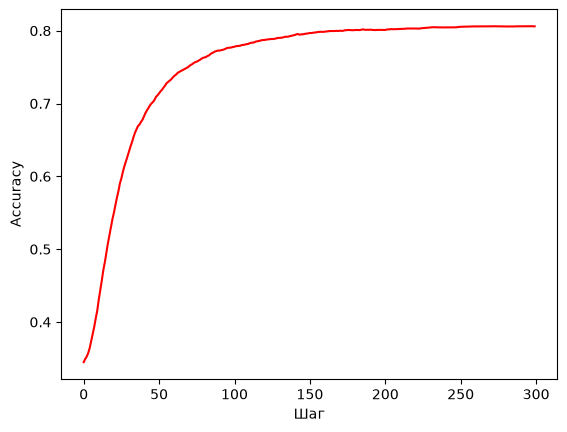

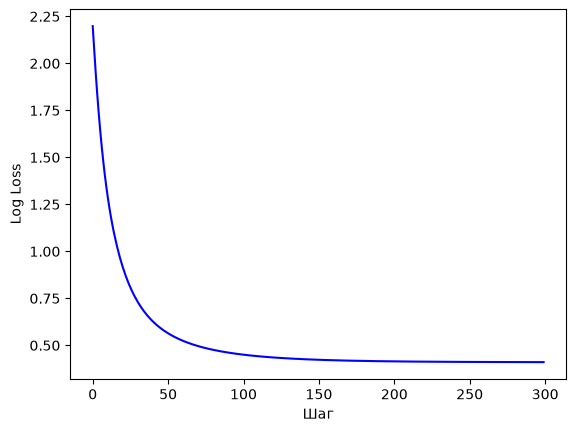

[ 0.01017035  1.          1.          1.          0.33878525  0.46318135
 -0.55729572 -0.13357076  1.         -0.73006475  1.         -0.78377896
  0.03822913 -1.212297   -0.62167566  1.          1.          1.
  1.         -0.93254589  1.          1.          0.14056243  1.
  1.          1.          1.          0.01680114  1.          1.
  0.06383764  1.          1.        ]
0.806


In [472]:
w1, a1, l1 = fit(train_embeddings, train_labels["topic_1"], 0.2, 300)
plt.plot(a1, color="red")
plt.xlabel("Шаг")
plt.ylabel("Accuracy")
plt.show()
plt.plot(l1, color="blue", label="log loss history")
plt.xlabel("Шаг")
plt.ylabel("Log Loss")
plt.show()
print(w1)
print(a1[-1])

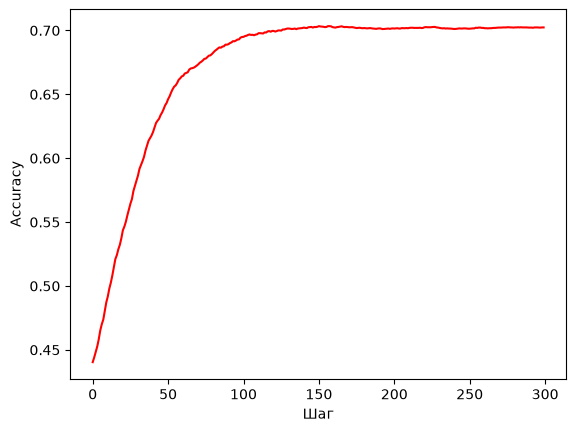

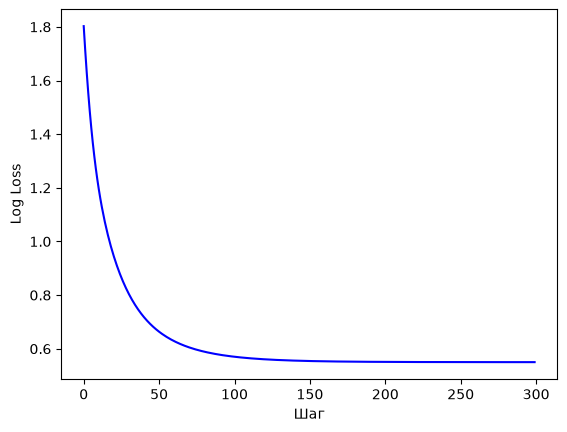

[-0.00990235  1.          1.          1.         -0.04212626 -0.48205718
 -0.25726421  0.30264846  1.         -0.01841496  1.         -0.39537986
 -0.07465013 -0.66464126  0.53980552  1.          1.          1.
  1.          0.49811409  1.          1.         -0.52433498  1.
  1.          1.          1.          0.17454566  1.          1.
  0.44976375  1.          1.        ]
0.702375


In [473]:
w2, a2, l2 = fit(train_embeddings, train_labels["topic_2"], 0.2, 300)
plt.plot(a2, color="red")
plt.xlabel("Шаг")
plt.ylabel("Accuracy")
plt.show()
plt.plot(l2, color="blue", label="log loss history")
plt.xlabel("Шаг")
plt.ylabel("Log Loss")
plt.show()
print(w2)
print(a2[-1])

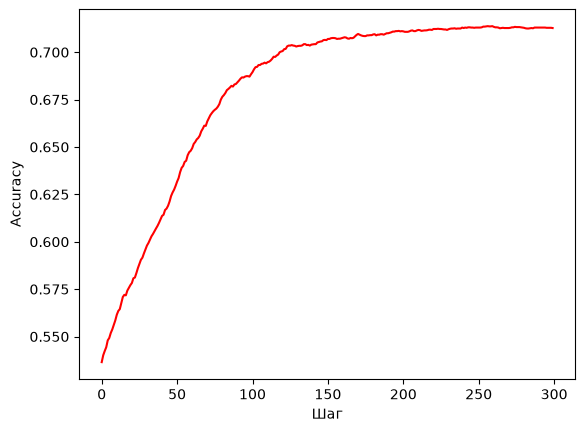

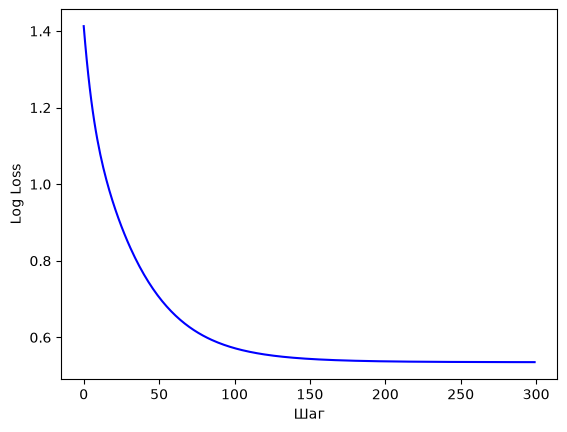

[ 0.04344167  1.          1.          1.          0.20137648 -0.47776132
  0.33747563  0.6889403   1.          0.2493777   1.         -0.09796704
 -0.64256087  0.43720549 -0.31632393  1.          1.          1.
  1.         -1.03861188  1.          1.         -0.14953093  1.
  1.          1.          1.         -0.15403905  1.          1.
  0.40891155  1.          1.        ]
0.71275


In [474]:
w3, a3, l3 = fit(train_embeddings, train_labels["topic_3"], 0.2, 300)
plt.plot(a3, color="red")
plt.xlabel("Шаг")
plt.ylabel("Accuracy")
plt.show()
plt.plot(l3, color="blue", label="log loss history")
plt.xlabel("Шаг")
plt.ylabel("Log Loss")
plt.show()
print(w3)
print(a3[-1])

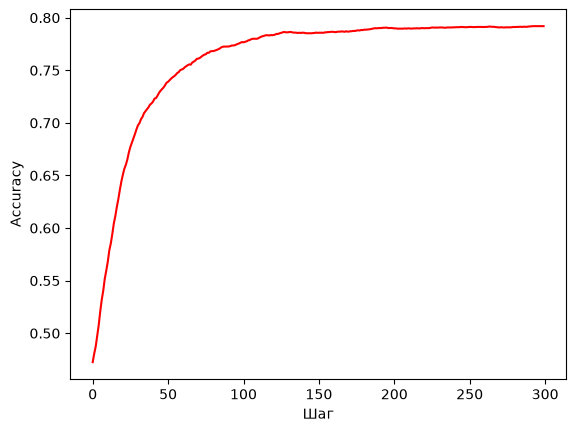

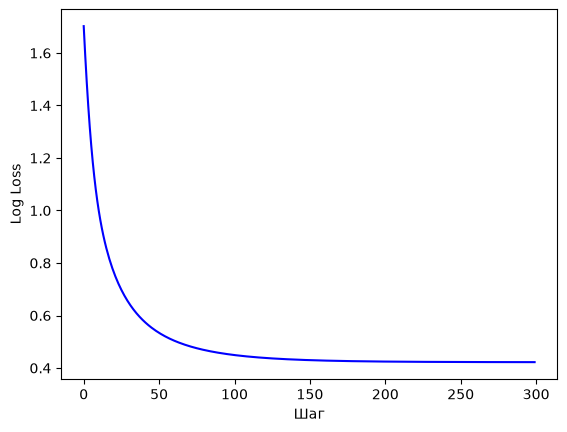

[ 0.01058098  1.          1.          1.         -0.44020815  0.321842
  0.65045986  0.20801018  1.          1.52145049  1.         -0.25411285
  0.78221443 -0.37739643 -1.17053997  1.          1.          1.
  1.         -0.05662844  1.          1.         -0.07060011  1.
  1.          1.          1.         -0.16017019  1.          1.
 -0.12167381  1.          1.        ]
0.792


In [475]:
w4, a4, l4 = fit(train_embeddings, train_labels["topic_4"], 0.2, 300)
plt.plot(a4, color="red")
plt.xlabel("Шаг")
plt.ylabel("Accuracy")
plt.show()
plt.plot(l4, color="blue", label="log loss history")
plt.xlabel("Шаг")
plt.ylabel("Log Loss")
plt.show()
print(w4)
print(a4[-1])

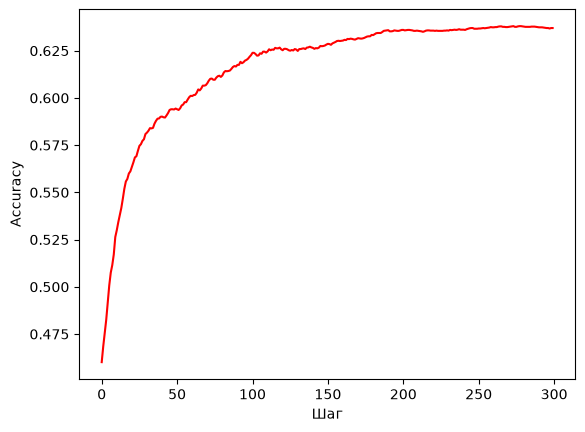

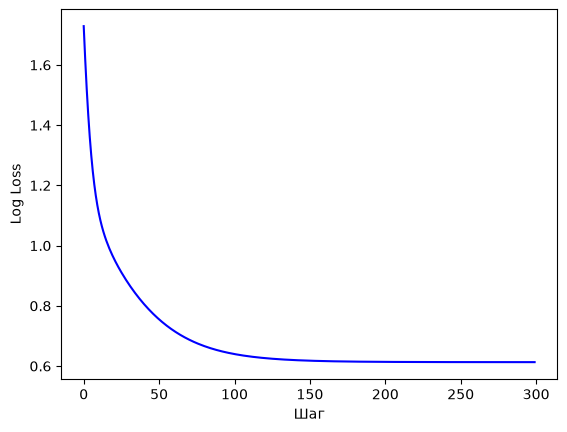

[-0.02940085  1.          1.          1.         -0.10570855  0.29742491
 -0.28073518  0.14951517  1.          0.17609752  1.          0.09405065
 -0.13893112  0.37037195 -0.17067566  1.          1.          1.
  1.          0.02078886  1.          1.         -0.33277248  1.
  1.          1.          1.         -0.47144099  1.          1.
  0.19801183  1.          1.        ]
0.637
27


In [476]:
ws, acs, ls = fit(train_embeddings, train_labels["source"], 0.2, 300)
plt.plot(acs, color="red")
plt.xlabel("Шаг")
plt.ylabel("Accuracy")
plt.show()
plt.plot(ls, color="blue", label="log loss history")
plt.xlabel("Шаг")
plt.ylabel("Log Loss")
plt.show()
print(ws)
print(acs[-1])
m = -1e9
ans = 0
for i in range(33):
    if ws[i] != 1 and abs(ws[i]) > m:
        ans = i
        m = abs(ws[i])
print(ans)

In [477]:
train_ids = np.zeros(train_labels.shape)
print(train_ids)
train_ids[:, 0] = train_labels["id"]
train_ids[:, 1] = ((train_embeddings @ w1) > 0.5)
train_ids[:, 2] = ((train_embeddings @ w2) > 0.5)
train_ids[:, 3] = ((train_embeddings @ w3) > 0.5)
train_ids[:, 4] = ((train_embeddings @ w4) > 0.5)
train_ids[:, 5] = ((train_embeddings @ ws) > 0.5)
print(train_ids)

[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]


ValueError: could not convert string to float: '0a7e1e0a8a73c9d77c6338c2'